In [ ]:
# imports
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

**Task 1: Verify your Google Cloud environment setup, including capturing proof of your active cloud notebook instance or billing credit balance.**

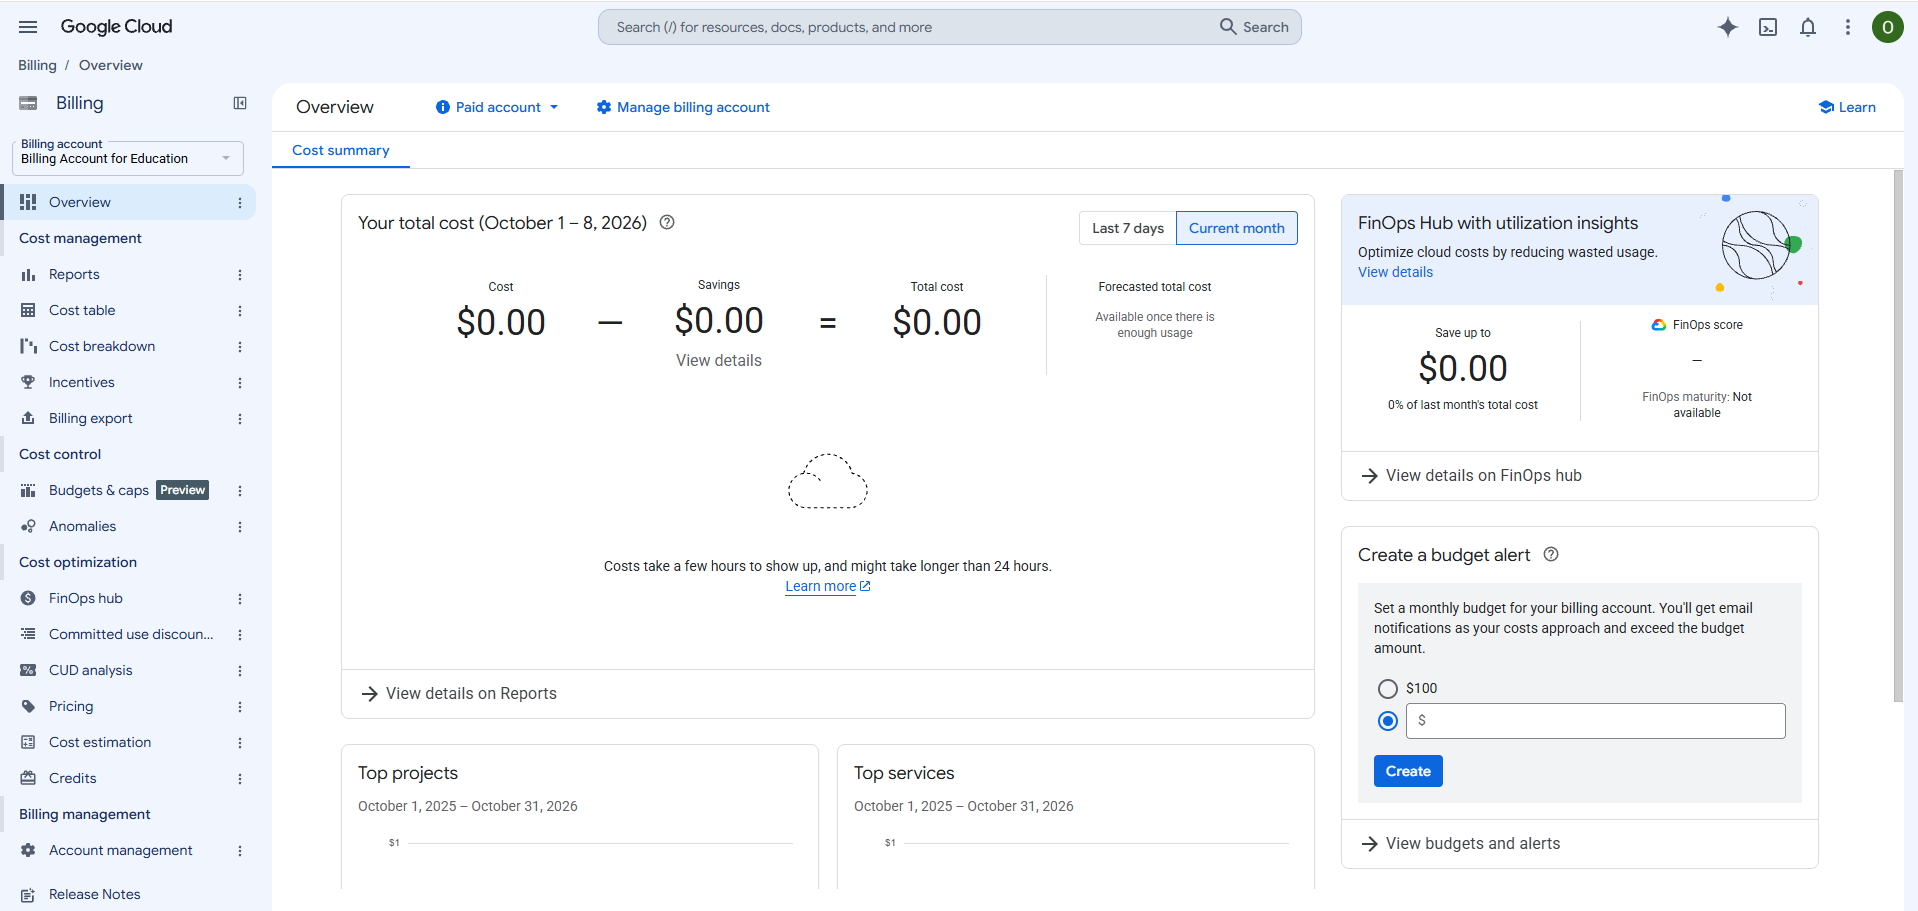

Note: my current cost is zero because I have not ran my notebook or connected it to a runtime yet.

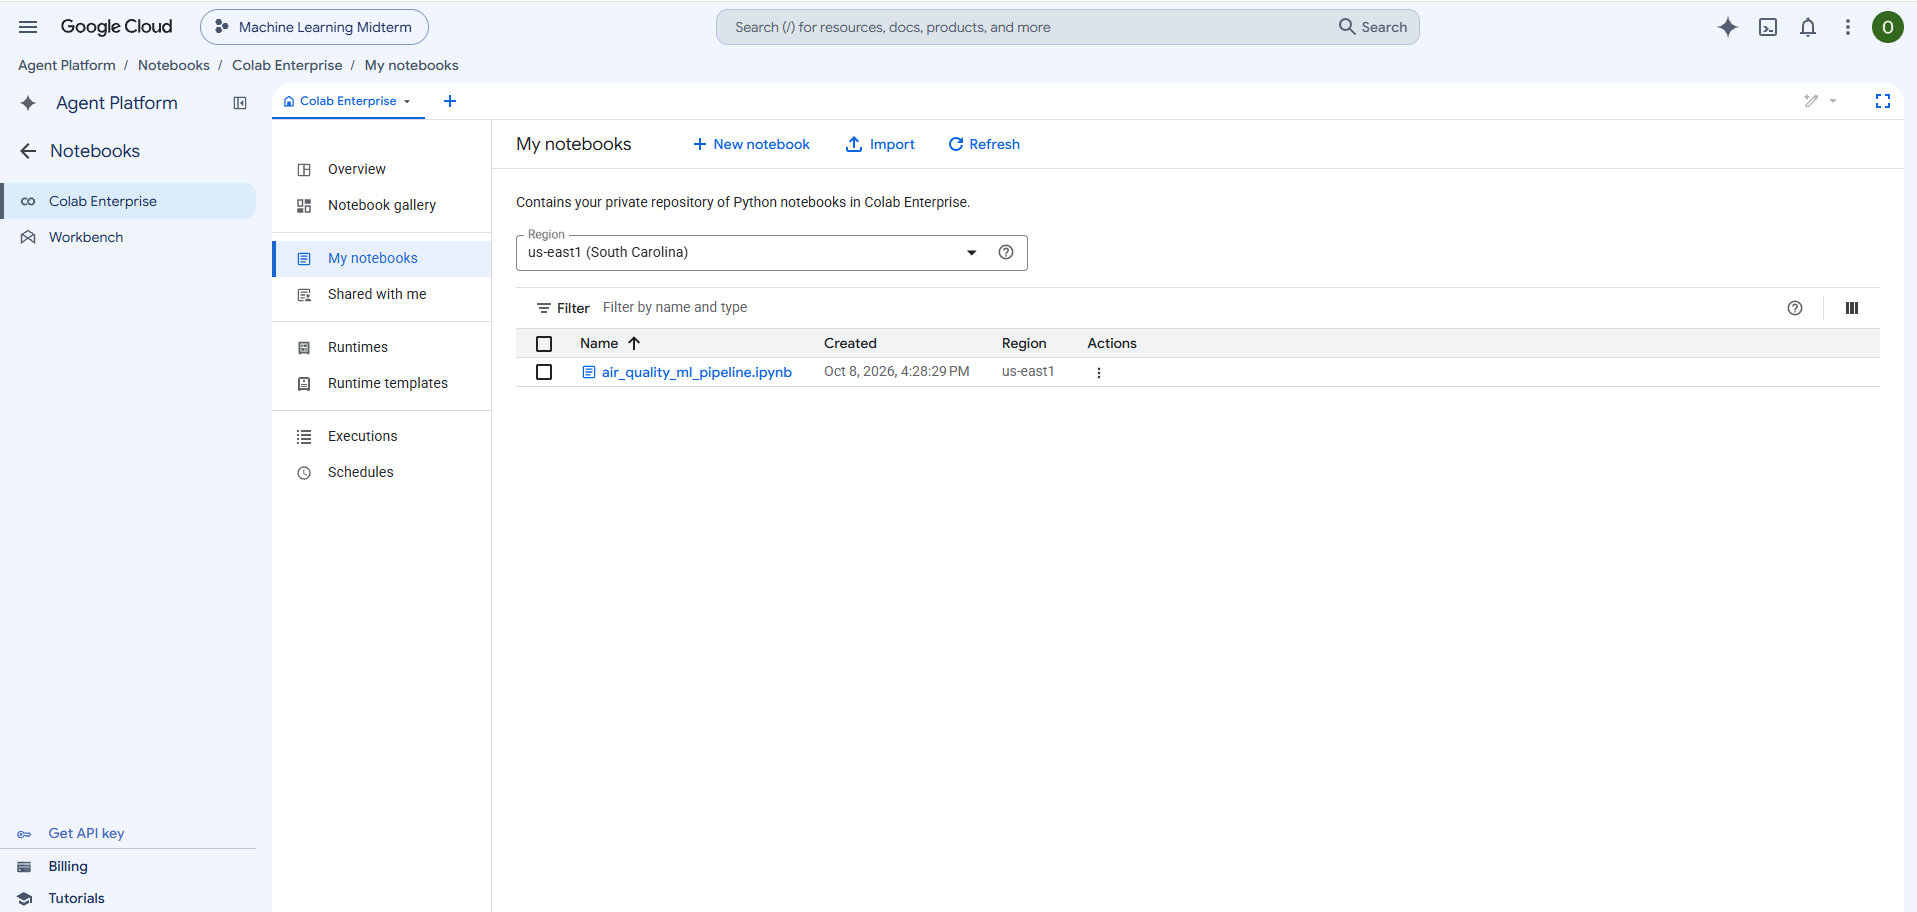

**Task 2: Load the dataset into a Pandas DataFrame using the official ucimlrepo package or direct data retrieval methods
linked to the UCI repository** (https://archive.ics.uci.edu/dataset/360/air+quality).

In [ ]:
!pip install ucimlrepo

Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 362, in run
    resolver = self.make_resolver(
               ^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 177, in make_resolver
    return pip._internal.resolution.resolvelib.resolver.Resolver(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/resolution/resolvelib/resolver.py", line 58, in __init__
    self.factory = Factory(
                   ^^^^^^^^
  File "/usr/local/lib/py

KeyboardInterrupt: 

In [ ]:
from ucimlrepo import fetch_ucirepo
air_quality = fetch_ucirepo(id=360)
df = air_quality.data.original

**Task 3: Use structural inspection methods (head(), info(), describe()) to analyze the dataset structure and examine feature distributions across sensor and meteorological variables.**

In [ ]:
df.head(1000)

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,4/21/2004,5:00:00,-200.0,871,-200,3.7,694,-200,1160,-200,1421,779,10.1,71.8,0.8880
996,4/21/2004,6:00:00,-200.0,1035,-200,8.7,929,-200,887,-200,1599,1009,10.2,70.9,0.8841
997,4/21/2004,7:00:00,-200.0,1513,-200,27.0,1480,-200,572,-200,2249,1595,11.8,66.0,0.9085
998,4/21/2004,8:00:00,-200.0,1726,-200,40.3,1776,-200,478,-200,2684,1940,14.0,58.2,0.9271


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   int64  
 4   NMHC(GT)       9357 non-null   int64  
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   int64  
 7   NOx(GT)        9357 non-null   int64  
 8   PT08.S3(NOx)   9357 non-null   int64  
 9   NO2(GT)        9357 non-null   int64  
 10  PT08.S4(NO2)   9357 non-null   int64  
 11  PT08.S5(O3)    9357 non-null   int64  
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(5), int64(8), object(2)
memory usage: 1.1+ MB


In [ ]:
df.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


**Task 4: Identify and handle implicit missing data values (such as the standard -200 sentinel values present in the air quality dataset) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.**

In [ ]:
print((df == -200).sum())

Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


In [ ]:
df = df.replace(-200, np.nan)

In [ ]:
df.isnull().sum()

,0
Date,0
Time,0
CO(GT),1683
PT08.S1(CO),366
NMHC(GT),8443
C6H6(GT),366
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642


In [ ]:
num_cols = ['CO(GT)', 'PT08.S1(CO)','NMHC(GT)','C6H6(GT)', 'PT08.S2(NMHC)','NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)','PT08.S5(O3)', 'T', 'RH', 'AH']
imputer = SimpleImputer(strategy='median')
df[num_cols] = imputer.fit_transform(df[num_cols])

In [ ]:
df.isnull().sum()

,0
Date,0
Time,0
CO(GT),0
PT08.S1(CO),0
NMHC(GT),0
C6H6(GT),0
PT08.S2(NMHC),0
NOx(GT),0
PT08.S3(NOx),0
NO2(GT),0


**Task 5: Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and necessary encoding to categorical/temporal features.**

In [ ]:
#Separated dates into days of the week and months so that I could meaningfully use OneHotEncoder
dates = pd.to_datetime(df['Date'])
df['DayOfWeek'] = dates.dt.dayofweek   # 0 = Monday, 6 = Sunday
df['Month'] = dates.dt.month           # 1 = January, 12 = December

num_attributes = ['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)',
                  'PT08.S2(NMHC)','NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)',
                  'PT08.S4(NO2)','PT08.S5(O3)', 'T', 'RH', 'AH']
cat_attributes = ['Time', 'DayOfWeek', 'Month']

transformation = ColumnTransformer([
    ("num", StandardScaler(), num_attributes),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_attributes),
])

pipeline = Pipeline([
    ("transformation", transformation),
])

**Task 6: Train classification models to predict air quality categories using standard logistic/softmax regression and an SGDClassifier configured with custom loss functions and hyperparameters, evaluating convergence speed and performance.**

In [ ]:
# Convert continuous CO(GT) into 3 equal-size classes: 0 = Low, 1 = Moderate, 2 = High
df['CO_Class'] = pd.qcut(df['CO(GT)'], q=3, labels=[0, 1, 2]).astype(int)

# Concentration range and size of each class
print(df.groupby('CO_Class')['CO(GT)'].agg(['min', 'max', 'count']))

          min   max  count
CO_Class                  
0         0.1   1.5   3175
1         1.6   2.1   3072
2         2.2  11.9   3110


In [ ]:
# Inputs: every numeric column except the target, plus the time features
num_features = [c for c in num_attributes if c != 'CO(GT)']
X = df[num_features + cat_attributes]
y = df['CO_Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Same setup as Task 5, but without CO(GT)
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_attributes),
])

print(X_train.shape, X_test.shape)

(7485, 15) (1872, 15)


In [ ]:
import time
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

models = {
    "Softmax (LogisticRegression)": LogisticRegression(max_iter=1000, random_state=42),
    "SGDClassifier (log_loss)": SGDClassifier(loss="log_loss", learning_rate="constant",
                                              eta0=0.01, max_iter=1000, tol=1e-3,
                                              random_state=42),
}

fitted = {}
for name, model in models.items():
    pipe = Pipeline([("preprocessor", clone(preprocessor)), ("classifier", model)])

    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    fitted[name] = pipe
    print(name)
    print(f"  Fit time: {fit_time:.3f} s | Iterations: {pipe.named_steps['classifier'].n_iter_}")
    print(f"  Test accuracy: {pipe.score(X_test, y_test):.4f}")
    print(f"  Test log-loss: {log_loss(y_test, pipe.predict_proba(X_test)):.4f}\n")

Softmax (LogisticRegression)
  Fit time: 0.302 s | Iterations: [75]
  Test accuracy: 0.8088
  Test log-loss: 0.4697

SGDClassifier (log_loss)
  Fit time: 0.112 s | Iterations: 24
  Test accuracy: 0.7965
  Test log-loss: 0.5297



In [ ]:
scalers = {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler()}

for scaler_name, scaler in scalers.items():
    # Same preprocessing as before, only the numeric scaler changes
    scaler_prep = ColumnTransformer([
        ("num", scaler, num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_attributes),
    ])

    for name, model in models.items():
        pipe = Pipeline([("preprocessor", scaler_prep), ("classifier", clone(model))])

        start = time.perf_counter()
        pipe.fit(X_train, y_train)
        fit_time = time.perf_counter() - start

        print(f"{scaler_name} | {name}")
        print(f"  Fit time: {fit_time:.3f} s | Iterations: {pipe.named_steps['classifier'].n_iter_}")
        print(f"  Test accuracy: {pipe.score(X_test, y_test):.4f}")
        print(f"  Test log-loss: {log_loss(y_test, pipe.predict_proba(X_test)):.4f}\n")

StandardScaler | Softmax (LogisticRegression)
  Fit time: 0.278 s | Iterations: [75]
  Test accuracy: 0.8088
  Test log-loss: 0.4697

StandardScaler | SGDClassifier (log_loss)
  Fit time: 0.110 s | Iterations: 24
  Test accuracy: 0.7965
  Test log-loss: 0.5297

MinMaxScaler | Softmax (LogisticRegression)
  Fit time: 0.312 s | Iterations: [82]
  Test accuracy: 0.7847
  Test log-loss: 0.5132

MinMaxScaler | SGDClassifier (log_loss)
  Fit time: 0.135 s | Iterations: 32
  Test accuracy: 0.7468
  Test log-loss: 0.5910



Softmax (LogisticRegression)
              precision    recall  f1-score   support

         Low       0.83      0.84      0.84       655
    Moderate       0.71      0.70      0.71       592
        High       0.88      0.87      0.88       625

    accuracy                           0.81      1872
   macro avg       0.81      0.81      0.81      1872
weighted avg       0.81      0.81      0.81      1872



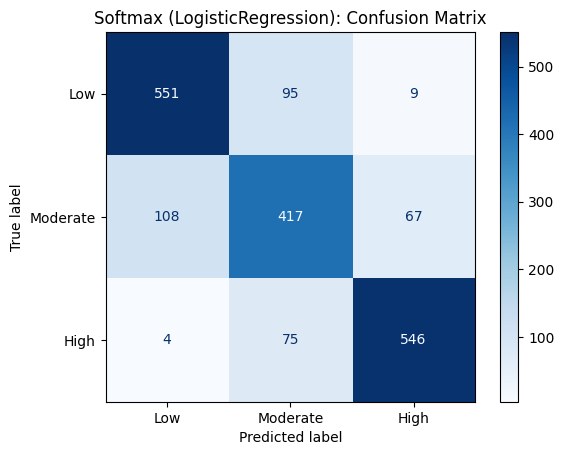

SGDClassifier (log_loss)
              precision    recall  f1-score   support

         Low       0.83      0.83      0.83       655
    Moderate       0.70      0.69      0.70       592
        High       0.85      0.86      0.86       625

    accuracy                           0.80      1872
   macro avg       0.79      0.79      0.79      1872
weighted avg       0.80      0.80      0.80      1872



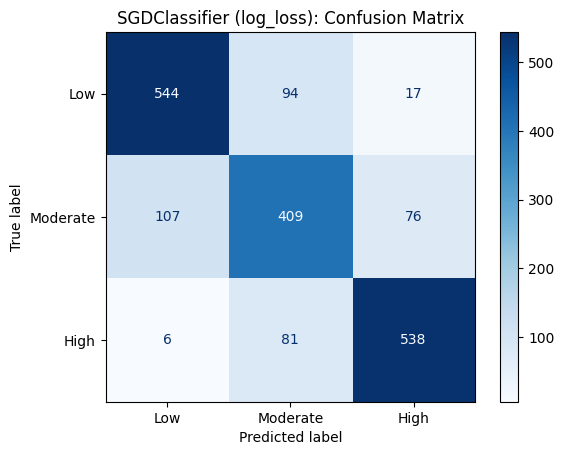

In [ ]:
for name, pipe in fitted.items():
    y_pred = pipe.predict(X_test)
    print(name)
    print(classification_report(y_test, y_pred, target_names=['Low', 'Moderate', 'High']))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Low', 'Moderate', 'High'],
                                            cmap='Blues', values_format='d')
    plt.title(f'{name}: Confusion Matrix')
    plt.show()

**Task 7: Transition to regression tasks to predict continuous pollutant concentrations, implementing baseline Linear Regression alongside Ridge (L2) and Lasso (L1) regularization, and analyzing how the regularization parameter impacts feature coefficients and feature selection.**

In [ ]:
# Same inputs as Task 6; the target is now the CO(GT) value itself
y_reg = df['CO(GT)']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)

# Baseline Linear Regression Pipeline (no regularization)
linear_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Create Ridge Regression Pipeline (L2 Regularization)
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0, random_state=42))
])

# Create Lasso Regression Pipeline (L1 Regularization)
lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=0.1, max_iter=5000, random_state=42))
])

# Fit all three pipelines
linear_pipeline.fit(Xr_train, yr_train)
ridge_pipeline.fit(Xr_train, yr_train)
lasso_pipeline.fit(Xr_train, yr_train)

# Generate predictions on the test set
y_pred_linear = linear_pipeline.predict(Xr_test)
y_pred_ridge = ridge_pipeline.predict(Xr_test)
y_pred_lasso = lasso_pipeline.predict(Xr_test)

# Evaluate each model
print("Linear Regression Metrics:")
print(f"RMSE: {np.sqrt(mean_squared_error(yr_test, y_pred_linear)):.4f} | R2: {r2_score(yr_test, y_pred_linear):.4f}")

print("\nRidge Regression (L2) Metrics:")
print(f"RMSE: {np.sqrt(mean_squared_error(yr_test, y_pred_ridge)):.4f} | R2: {r2_score(yr_test, y_pred_ridge):.4f}")

print("\nLasso Regression (L1) Metrics:")
print(f"RMSE: {np.sqrt(mean_squared_error(yr_test, y_pred_lasso)):.4f} | R2: {r2_score(yr_test, y_pred_lasso):.4f}")

Linear Regression Metrics:
RMSE: 0.5117 | R2: 0.8604

Ridge Regression (L2) Metrics:
RMSE: 0.5118 | R2: 0.8603

Lasso Regression (L1) Metrics:
RMSE: 0.6075 | R2: 0.8032


In [ ]:
# Define a range of alpha values to test
alpha_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
n_num = len(num_features)  # numeric features come first in the coefficient list

# Ridge: record the numeric coefficients at each alpha
ridge_table = pd.DataFrame(index=num_features)
for a in alpha_values:
    ridge_exp = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', Ridge(alpha=a, random_state=42))
    ])
    ridge_exp.fit(Xr_train, yr_train)
    ridge_table[f'alpha={a}'] = ridge_exp.named_steps['regressor'].coef_[:n_num]

# Lasso: same, plus count how many coefficients were set to zero
lasso_table = pd.DataFrame(index=num_features)
for a in alpha_values:
    lasso_exp = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', Lasso(alpha=a, max_iter=5000, random_state=42))
    ])
    lasso_exp.fit(Xr_train, yr_train)
    coefs = lasso_exp.named_steps['regressor'].coef_
    lasso_table[f'alpha={a}'] = coefs[:n_num]
    print(f"Lasso alpha={a}: {np.sum(coefs == 0)} of {len(coefs)} coefficients are zero "
          f"({np.sum(coefs[n_num:] == 0)} of them are time columns)")

print("\nRidge coefficients (numeric features):")
print(ridge_table.round(4))
print("\nLasso coefficients (numeric features):")
print(lasso_table.round(4))

Lasso alpha=0.001: 9 of 55 coefficients are zero (9 of them are time columns)
Lasso alpha=0.01: 39 of 55 coefficients are zero (36 of them are time columns)
Lasso alpha=0.1: 49 of 55 coefficients are zero (43 of them are time columns)
Lasso alpha=1.0: 54 of 55 coefficients are zero (43 of them are time columns)
Lasso alpha=10.0: 55 of 55 coefficients are zero (43 of them are time columns)
Lasso alpha=100.0: 55 of 55 coefficients are zero (43 of them are time columns)

Ridge coefficients (numeric features):
               alpha=0.001  alpha=0.01  alpha=0.1  alpha=1.0  alpha=10.0  \
PT08.S1(CO)         0.1065      0.1065     0.1066     0.1073      0.1131   
NMHC(GT)            0.1469      0.1469     0.1469     0.1470      0.1480   
C6H6(GT)            0.4172      0.4172     0.4166     0.4110      0.3658   
PT08.S2(NMHC)      -0.4526     -0.4525    -0.4513    -0.4401     -0.3468   
NOx(GT)             0.7313      0.7313     0.7312     0.7310      0.7278   
PT08.S3(NOx)       -0.0071     -

**Task 8: Provide a final documentation cell or appendix section containing a screenshot or export of your Google Cloud billing or resource utilization dashboard showing active credit consumption.**

Screenshot of Credits Dashboard
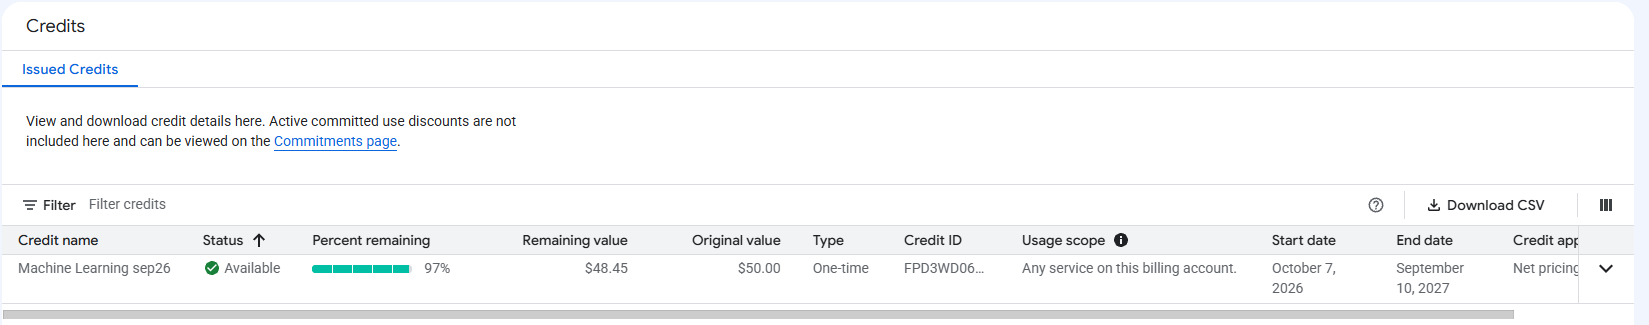

Screenshot of Billing Report Dashboard
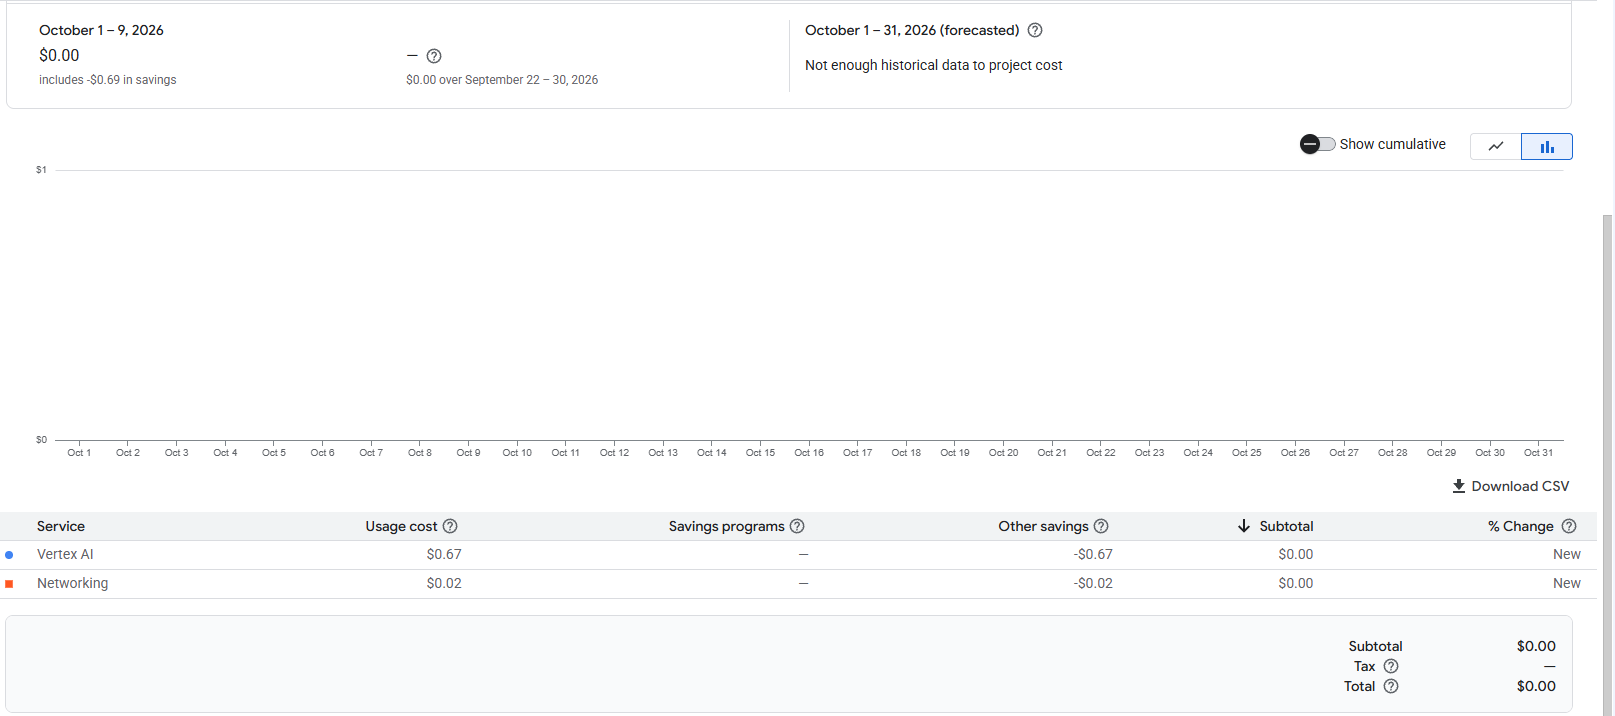